In [13]:
""" Task 5: Moving Average Temperature """

' Task 5: Moving Average Temperature '

DataFrame 'df' successfully created!


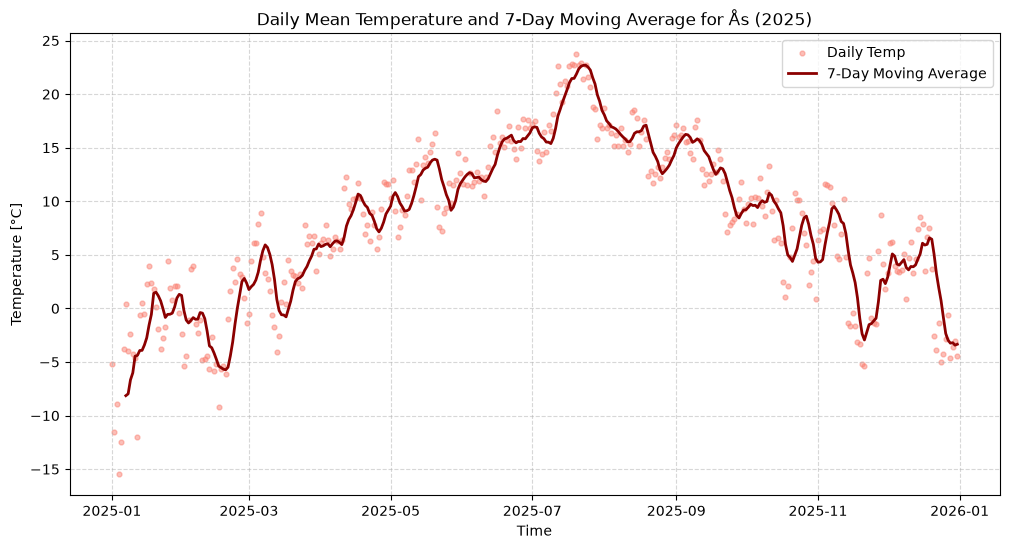

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)', 
    'referencetime': '2025-01-01/2026-01-01'
}
client_id = "unique-client-id" #write your unique client id here
response = requests.get(endpoint, params=parameters, auth=(client_id, ''))
if response.status_code == 200:
    payload = response.json()
    data = [{
        "Time": pd.to_datetime(entry["referenceTime"]),
        "Average daily temperature [C]": entry["observations"][0]["value"]
    } for entry in payload.get("data", [])]
    
    df = pd.DataFrame(data)
    print("DataFrame 'df' successfully created!")


df['Moving_Avg'] = df['Average daily temperature [C]'].rolling(window=7, min_periods=7).mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(df['Time'], df['Average daily temperature [C]'], color='salmon', s=12, alpha=0.5, label='Daily Temp')
ax.plot(df['Time'], df['Moving_Avg'], color='darkred', linewidth=2, label='7-Day Moving Average')
ax.set_xlabel('Time')
ax.set_ylabel('Temperature [°C]')
ax.set_title('Daily Mean Temperature and 7-Day Moving Average for Ås (2025)')
ax.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

We see from the plot that our seven day moving average successfully has filtered out some of the worst 'outliers' and the average doesnt rise or fall significantly unless we have heaps of high or low readings compared to the average.